### Method 1: Upload via the Files Sidebar (No Code Needed)
1. Click the **Folder icon** (📁) on the left sidebar of Colab.
2. Click the **Upload to session storage** icon (page with an up arrow).
3. Select your file from your desktop.
4. Once uploaded, hover over the file, click the three dots, select **Copy path**, and load it into pandas:

```python
import pandas as pd
df = pd.read_csv('/content/your_file_name.csv')
```
*Note: Files uploaded this way are deleted when your runtime disconnects.*

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from sklearn.linear_model import Perceptron
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.utils import to_categorical
import warnings
warnings.filterwarnings('ignore')

In [41]:
df = pd.read_csv('/content/weatherAUS.csv')
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  object 
 1   Location       145460 non-null  object 
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  object 
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  object 
 10  WindDir3pm     141232 non-null  object 
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null

In [43]:
df.isnull().sum()

,0
Date,0
Location,0
MinTemp,1485
MaxTemp,1261
Rainfall,3261
Evaporation,62790
Sunshine,69835
WindGustDir,10326
WindGustSpeed,10263
WindDir9am,10566


<Axes: xlabel='RainTomorrow', ylabel='count'>

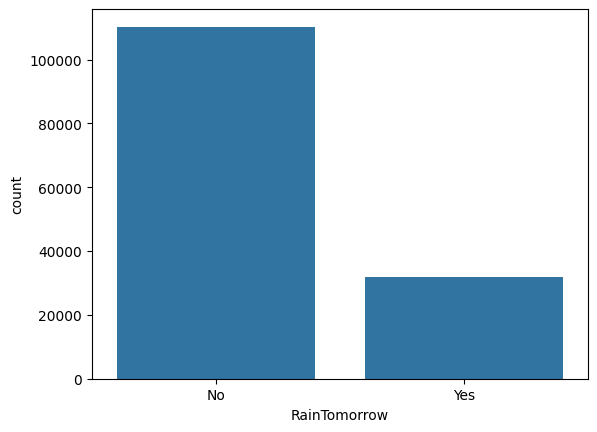

In [44]:
sns.countplot(x=df['RainTomorrow'])

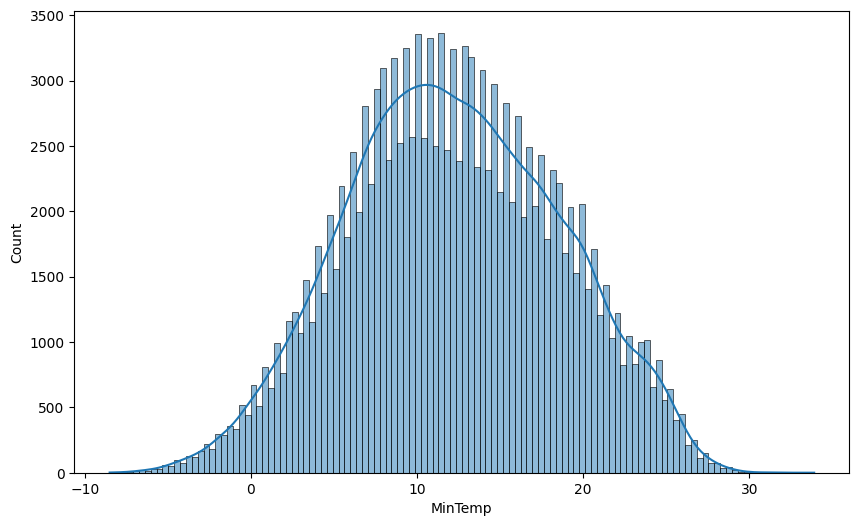

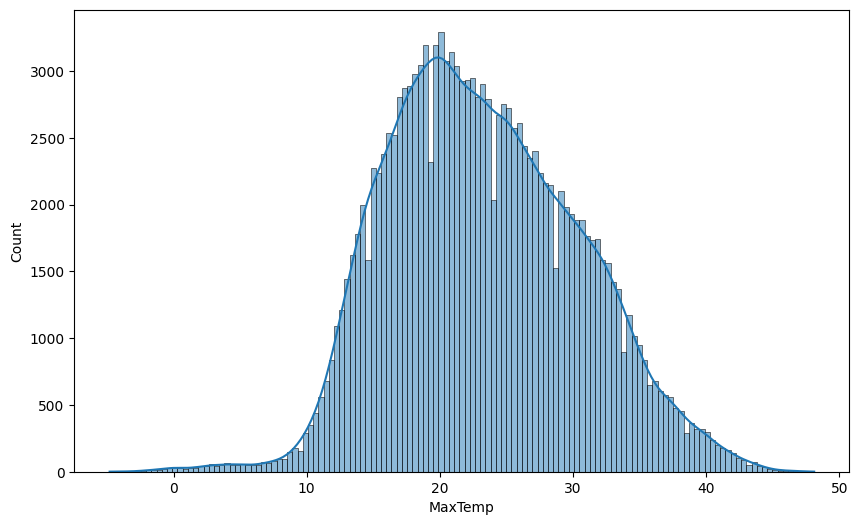

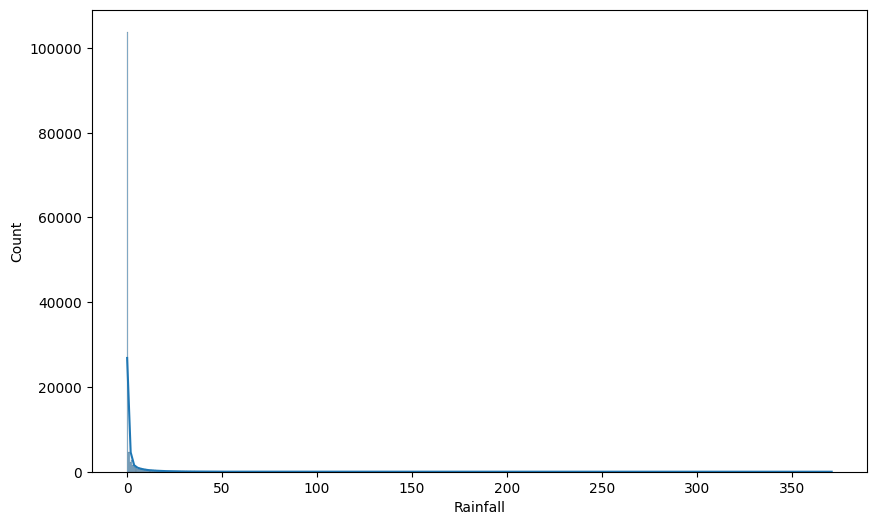

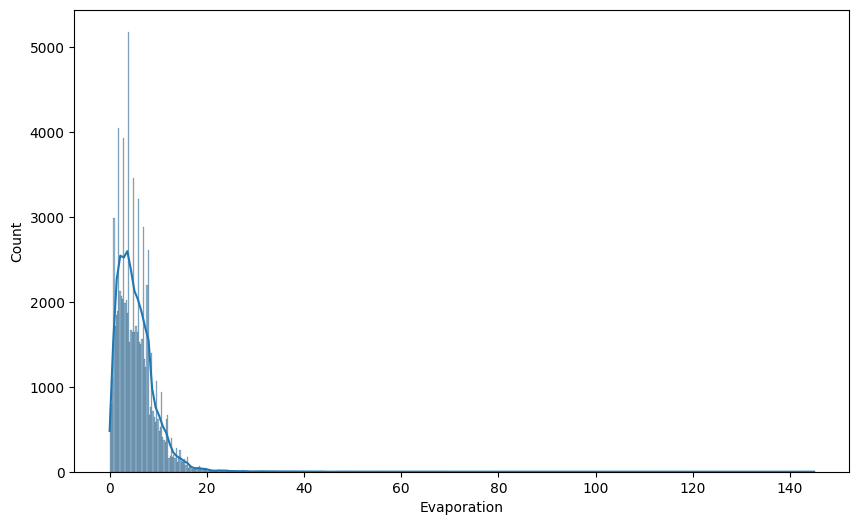

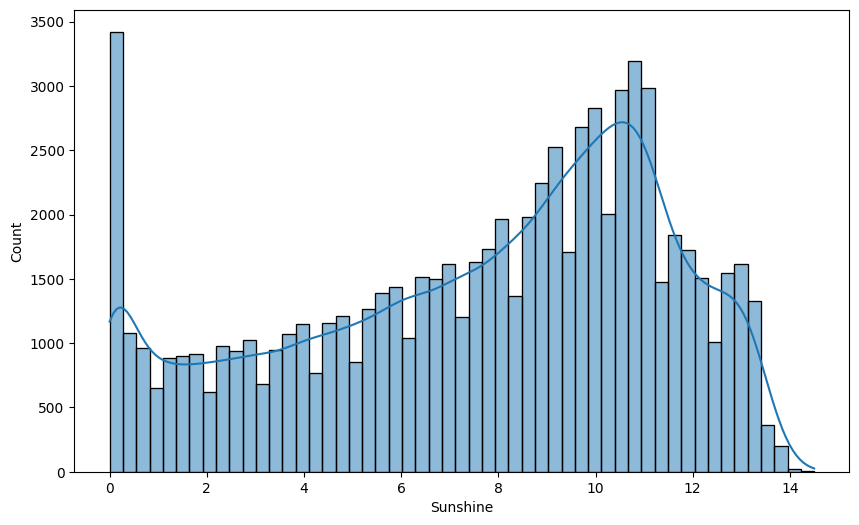

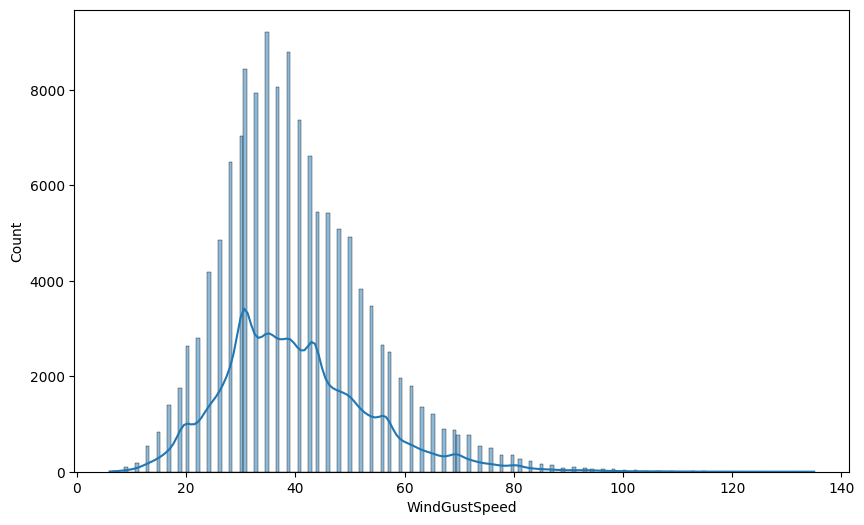

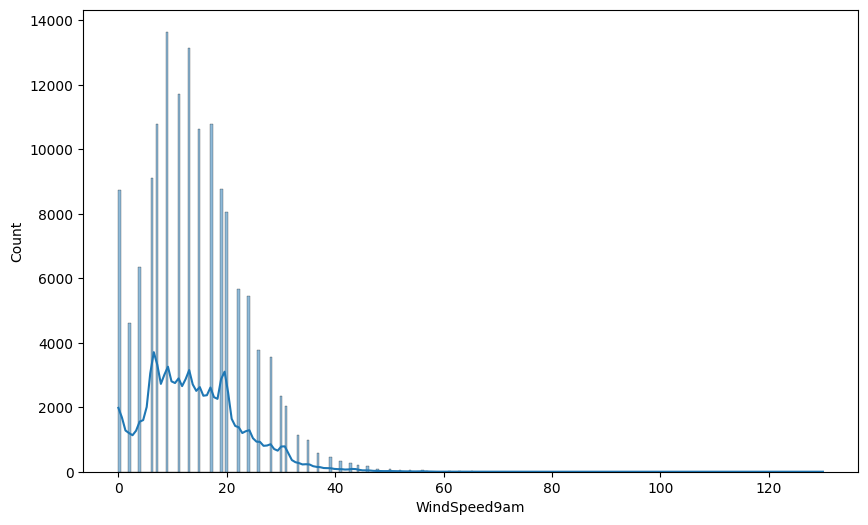

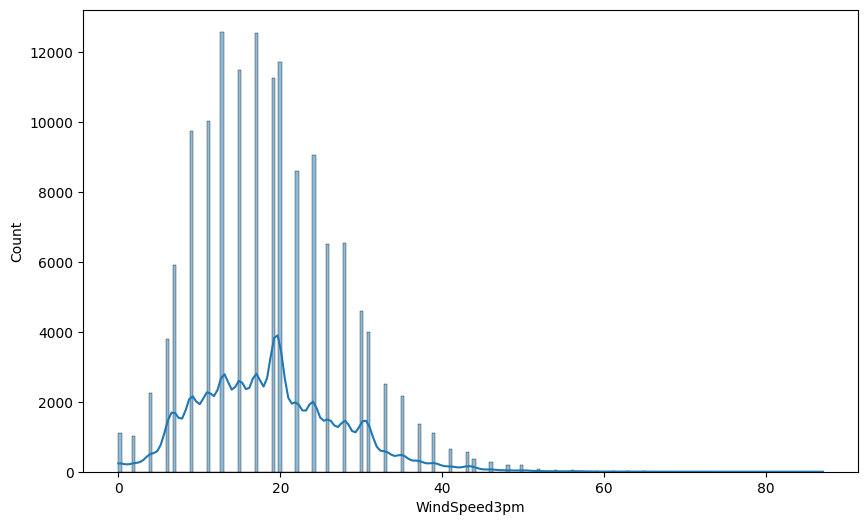

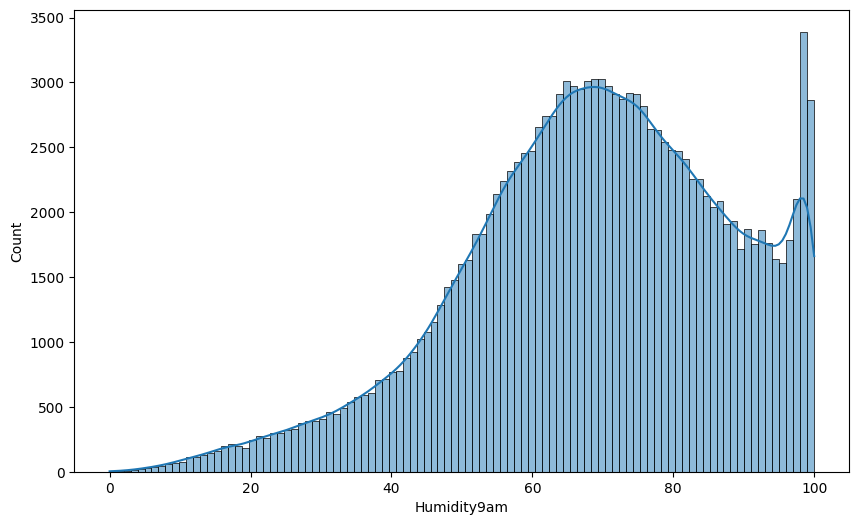

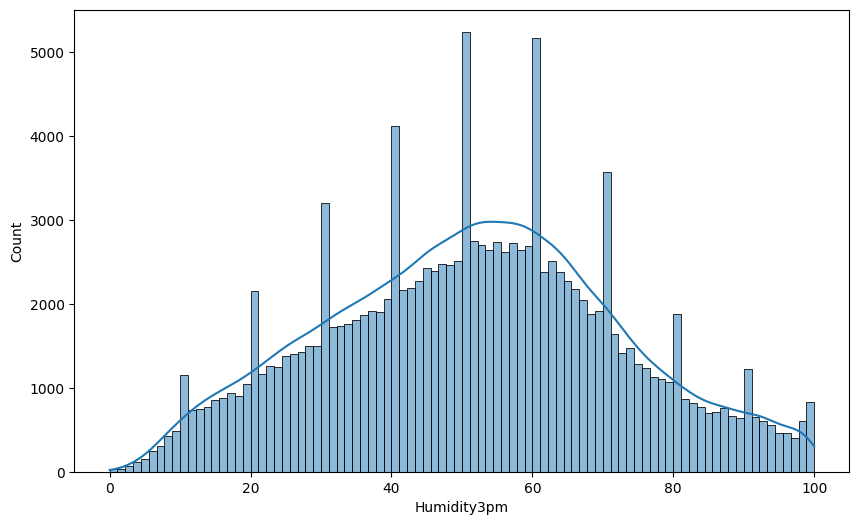

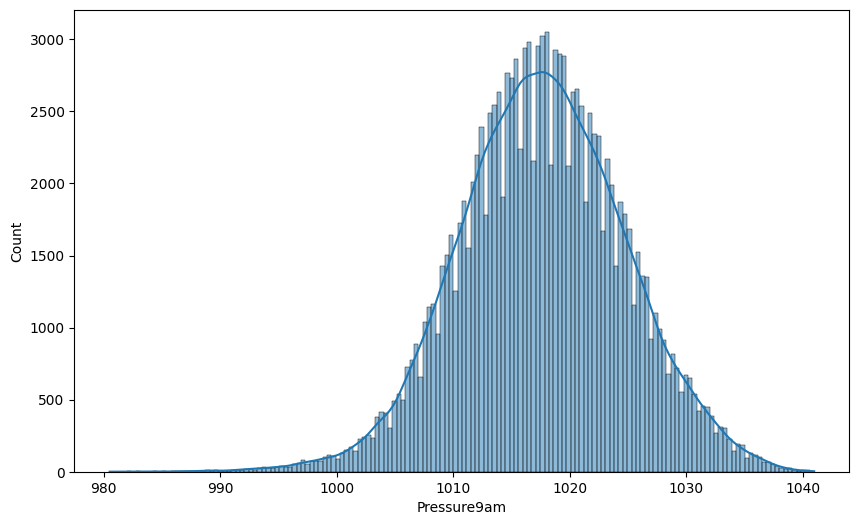

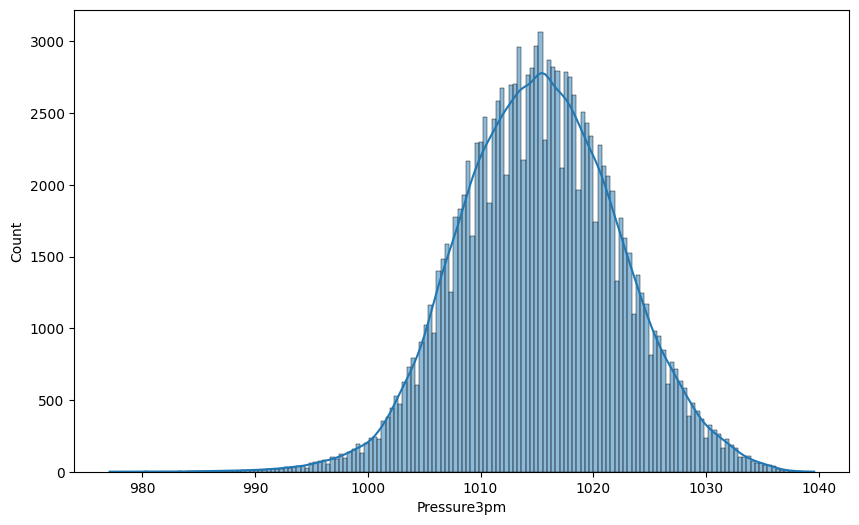

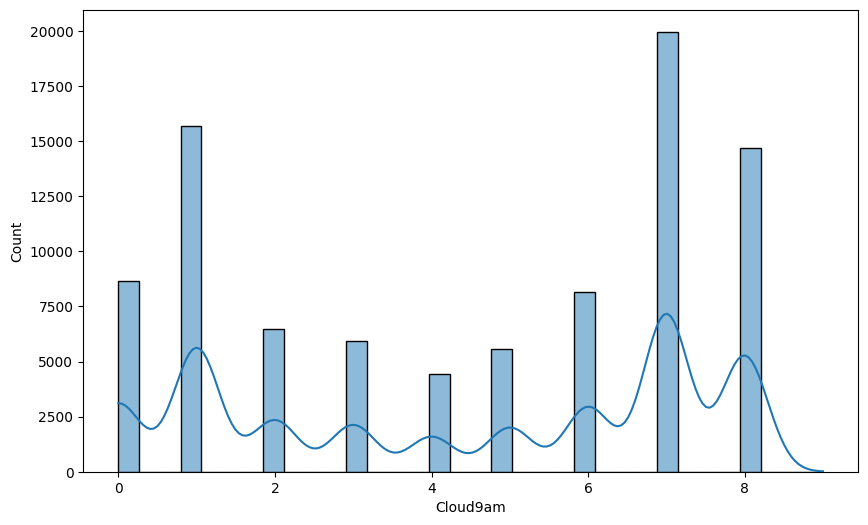

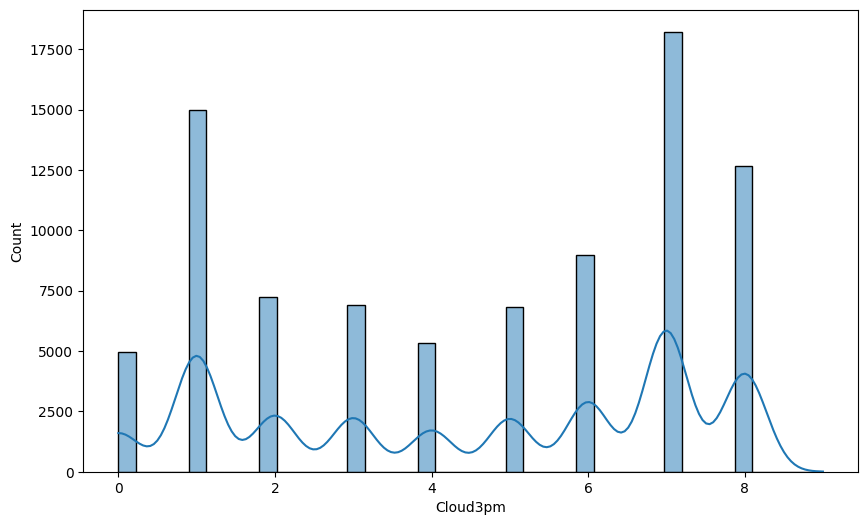

In [45]:
Num_col=['MinTemp','MaxTemp','Rainfall','Evaporation','Sunshine','WindGustSpeed','WindSpeed9am','WindSpeed3pm','Humidity9am','Humidity3pm','Pressure9am','Pressure3pm','Cloud9am','Cloud3pm']
for col in Num_col:
  plt.figure(figsize=(10,6))
  sns.histplot(df[col],kde=True)

In [46]:
df['Date']= pd.to_datetime(df["Date"])
df['year'] = df.Date.dt.year


def encode(data, col, max_val):
    data[col + '_sin'] = np.sin(2 * np.pi * data[col]/max_val)
    data[col + '_cos'] = np.cos(2 * np.pi * data[col]/max_val)
    return data

df['month'] = df.Date.dt.month
df = encode(df, 'month', 12)

df['day'] = df.Date.dt.day
df = encode(df, 'day', 31)

df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Temp3pm,RainToday,RainTomorrow,year,month,month_sin,month_cos,day,day_sin,day_cos
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,21.8,No,No,2008,12,-2.449294e-16,1.0,1,0.201299,0.979530
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,24.3,No,No,2008,12,-2.449294e-16,1.0,2,0.394356,0.918958
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,23.2,No,No,2008,12,-2.449294e-16,1.0,3,0.571268,0.820763
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,26.5,No,No,2008,12,-2.449294e-16,1.0,4,0.724793,0.688967
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,29.7,No,No,2008,12,-2.449294e-16,1.0,5,0.848644,0.528964


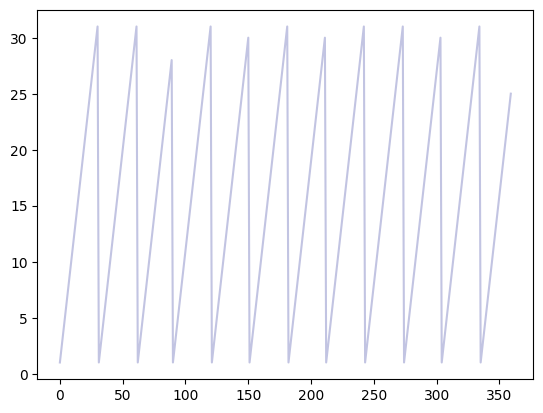

In [47]:
section = df[:360]
tm = section["day"].plot(color="#C2C4E2")

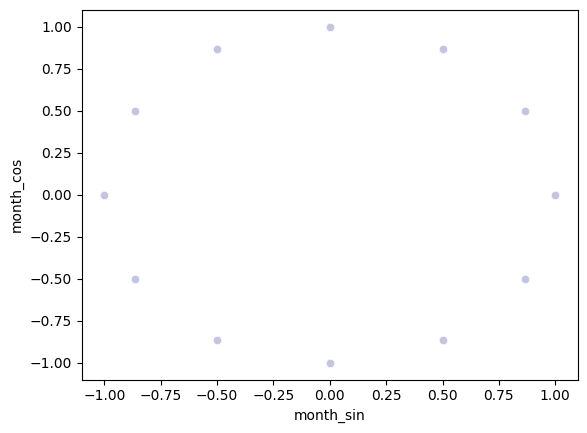

In [48]:

cyclic_month = sns.scatterplot(x="month_sin",y="month_cos",data=df, color="#C2C4E2")

In [49]:
cat_col = df.select_dtypes(include=['object']).columns
cat_col

Index(['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday',
       'RainTomorrow'],
      dtype='object')

In [67]:
"""
DEBUGGING SUMMARY & EXPLANATION:

1. ERROR 1: ValueError: Invalid dtype: object during model.fit()
   - Why it occurred:
     The neural network was being trained on `X_Train_Scaled` which still
     contained string (object) columns like 'Location' and 'WindGustDir'.
     Neural networks require purely numerical input matrices.
   - How we debugged it:
     We performed One-Hot Encoding using `pd.get_dummies()` to convert
     the string columns to binary (0/1) columns before splitting and scaling.

2. ERROR 2: Input shape mismatch (expected 26, received 117)
   - Why it occurred:
     The first Dense layer in our model was hardcoded with `input_dim = 26`.
     After one-hot encoding, our features increased from 26 to 117 columns.
   - How we debugged it:
     We updated the model's first layer to `input_dim = X_train_scaled.shape[1]`
     (which dynamically adapts to 117) and re-compiled the model to update the structural weights.
"""
# Let's verify the current missing values status:
df[cat_col].isnull().sum()

,0
Location,0
WindGustDir,0
WindDir9am,0
WindDir3pm,0
RainToday,0
RainTomorrow,0


In [51]:
df.shape

(145460, 30)

In [52]:
num_col=df.select_dtypes(include=['float64']).columns
num_col

Index(['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
       'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am',
       'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm',
       'Temp9am', 'Temp3pm', 'month_sin', 'month_cos', 'day_sin', 'day_cos'],
      dtype='object')

In [53]:
df[num_col].isnull().sum()

,0
MinTemp,1485
MaxTemp,1261
Rainfall,3261
Evaporation,62790
Sunshine,69835
WindGustSpeed,10263
WindSpeed9am,1767
WindSpeed3pm,3062
Humidity9am,2654
Humidity3pm,4507


In [54]:
for col in cat_col:
    df[col] = df[col].fillna(df[col].mode()[0])
df[cat_col].isnull().sum()

,0
Location,0
WindGustDir,0
WindDir9am,0
WindDir3pm,0
RainToday,0
RainTomorrow,0


In [55]:
X=df.drop(columns=['RainTomorrow','Date'])
y=df['RainTomorrow']
encoder=LabelEncoder()


In [56]:
y_encoded=encoder.fit_transform(y)

In [57]:
X_train, X_test, y_train, y_test = train_test_split( X, y_encoded, test_size=0.2, random_state=42)

```markdown
### One-Hot Encoding Categorical Columns
We will use `pd.get_dummies` to one-hot encode our categorical variables. This converts categorical columns into multiple binary (0 or 1) columns so that your neural network can train on them.
```

In [58]:
# Identify categorical columns to encode (excluding 'Date' and the target 'RainTomorrow')
categorical_cols = ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']

# One-hot encode these columns
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Prepare features (X) and target (y)
# Drop columns not used for training
X_encoded = df_encoded.drop(columns=['RainTomorrow', 'Date'])
y_encoded = LabelEncoder().fit_transform(df_encoded['RainTomorrow'])

# Split the one-hot encoded dataset
X_train_enc, X_test_enc, y_train, y_test = train_test_split(
    X_encoded, y_encoded, test_size=0.2, random_state=42
)

# Verify the new shape (the number of columns will increase due to encoding)
print(f"New features shape: {X_train_enc.shape}")

New features shape: (116368, 117)


```markdown
Now we will fit the scaler on the numeric columns using our newly split training data and transform both the train and test subsets.
```

In [59]:
# Scale numeric columns on our new encoded splits
scaler = StandardScaler()

# Create copies to preserve structure
X_train_scaled = X_train_enc.copy()
X_test_scaled = X_test_enc.copy()

# Fit and transform numeric columns
X_train_scaled[num_col] = scaler.fit_transform(X_train_enc[num_col])
X_test_scaled[num_col] = scaler.transform(X_test_enc[num_col])

# Convert boolean True/False generated by get_dummies to 1/0 for safe tensor processing
for col in X_train_scaled.columns:
    if X_train_scaled[col].dtype == 'bool':
        X_train_scaled[col] = X_train_scaled[col].astype(int)
        X_test_scaled[col] = X_test_scaled[col].astype(int)

# Display a preview of the processed training features
display(X_train_scaled.head())

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,...,WindDir3pm_NW,WindDir3pm_S,WindDir3pm_SE,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW,RainToday_Yes
111548,0.359847,-0.761439,1.384638,NaN,NaN,NaN,-1.575595,NaN,1.319563,NaN,...,0,0,1,0,0,0,0,0,0,1
142528,1.938043,2.287383,-0.278643,1.557566,NaN,-0.662904,-0.566472,-0.188625,-0.889180,-1.469915,...,1,0,0,0,0,0,0,0,0,0
65304,0.391099,0.474950,-0.255216,-0.539915,0.102245,-0.736266,-0.790722,-0.868970,0.951439,0.262168,...,0,1,0,0,0,0,0,0,0,0
40651,0.953624,0.474950,-0.278643,NaN,NaN,-0.882991,-0.342222,0.378330,0.530726,0.743302,...,0,0,0,1,0,0,0,0,0,0
97487,-0.124549,-0.550691,-0.208363,-0.730595,0.340011,-0.662904,-0.117973,0.038157,-0.310700,-0.218966,...,0,0,0,0,1,0,0,0,0,0


### Fixing NaN Loss: Imputing Numerical Columns
Let's fill the missing values in our numerical columns with their median values so the neural network doesn't run into `nan` calculations.

In [68]:

for col in num_col:
    median_val = df_encoded[col].median()
    df_encoded[col] = df_encoded[col].fillna(median_val)

missing_count = df_encoded.isnull().sum().sum()
print(f"Total missing values remaining in the encoded DataFrame: {missing_count}")

Total missing values remaining in the encoded DataFrame: 0


Now we rebuild the splits and apply scaling safely on the fully imputed dataset.

In [69]:

X_encoded = df_encoded.drop(columns=['RainTomorrow', 'Date'])
y_encoded = LabelEncoder().fit_transform(df_encoded['RainTomorrow'])


X_train_enc, X_test_enc, y_train, y_test = train_test_split(
    X_encoded, y_encoded, test_size=0.2, random_state=42
)


scaler = StandardScaler()
X_train_scaled = X_train_enc.copy()
X_test_scaled = X_test_enc.copy()


X_train_scaled[num_col] = scaler.fit_transform(X_train_enc[num_col])
X_test_scaled[num_col] = scaler.transform(X_test_enc[num_col])


for col in X_train_scaled.columns:
    if X_train_scaled[col].dtype == 'bool':
        X_train_scaled[col] = X_train_scaled[col].astype(int)
        X_test_scaled[col] = X_test_scaled[col].astype(int)


y_train_cat = to_categorical(y_train, num_classes=2)
y_test_cat = to_categorical(y_test, num_classes=2)

print("Data preparation complete with zero missing values!")

Data preparation complete with zero missing values!


In [62]:
scaler=StandardScaler()
X_Train_Scaled = X_train.copy()
X_Test_scaled = X_test.copy()
X_Train_Scaled[num_col]=scaler.fit_transform(X_train[num_col])
X_Test_scaled[num_col]=scaler.transform(X_test[num_col])

In [63]:
y_train_cat = to_categorical(y_train,num_classes = 2)
y_test_cat = to_categorical(y_test,num_classes = 2)


In [64]:
model = Sequential([
    Dense(units = 32, kernel_initializer = 'uniform', activation = 'relu', input_dim = X_train_scaled.shape[1]),
    Dense(units = 32, kernel_initializer = 'uniform', activation = 'relu'),
    Dense(units = 16, kernel_initializer = 'uniform', activation = 'relu'),
    Dense(units = 8, kernel_initializer = 'uniform', activation = 'relu'),
    Dense(units = 1, kernel_initializer = 'uniform', activation = 'sigmoid')
])

In [73]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [74]:

history = model.fit(X_train_scaled, y_train,
                    epochs = 20, batch_size = 32, validation_split = 0.2, verbose = 1)

Epoch 1/20
2910/2910 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - accuracy: 0.8170 - loss: 0.4226 - val_accuracy: 0.8287 - val_loss: 0.3908
Epoch 2/20
2910/2910 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8375 - loss: 0.3738 - val_accuracy: 0.8332 - val_loss: 0.3842
Epoch 3/20
2910/2910 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8402 - loss: 0.3687 - val_accuracy: 0.8433 - val_loss: 0.3637
Epoch 4/20
2910/2910 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.8419 - loss: 0.3654 - val_accuracy: 0.8433 - val_loss: 0.3650
Epoch 5/20
2910/2910 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - accuracy: 0.8429 - loss: 0.3631 - val_accuracy: 0.8430 - val_loss: 0.3651
Epoch 6/20
2910/2910 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 0.8439 - loss: 0.3622 - val_accuracy: 0.8461 - val_loss: 0.3640
Epoch 7/20
2910/2910 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8446 - loss: 0.3610 - val_accuracy: 0.8413 - val_loss: 0.3658
Epoch 8/20
2910/2910 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8440 - loss: 0

In [75]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 32)             │         3,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,517 (64.52 KB)

 Trainable params: 5,505 (21.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 11,012 (43.02 KB)

In [76]:
import pickle
import json
from google.colab import files

# 1. Save and download the Keras Neural Network Model
model.save('weather_model.keras')
print("Model successfully saved as 'weather_model.keras'")

# 2. Save and download the fitted StandardScaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print("Scaler successfully saved as 'scaler.pkl'")

# 3. Create, save, and download the Metadata (column configurations & original categories)
metadata = {
    'encoded_columns': list(X_train_scaled.columns),
    'numerical_columns': list(num_col),
    'categories': {
        'Location': sorted(df['Location'].dropna().unique().tolist()),
        'WindGustDir': sorted(df['WindGustDir'].dropna().unique().tolist()),
        'WindDir9am': sorted(df['WindDir9am'].dropna().unique().tolist()),
        'WindDir3pm': sorted(df['WindDir3pm'].dropna().unique().tolist()),
        'RainToday': sorted(df['RainToday'].dropna().unique().tolist())
    }
}

with open('model_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=4)
print("Metadata successfully saved as 'model_metadata.json'")

# Trigger browser downloads for all 3 files
files.download('weather_model.keras')
files.download('scaler.pkl')
files.download('model_metadata.json')


Model successfully saved as 'weather_model.keras'
Scaler successfully saved as 'scaler.pkl'
Metadata successfully saved as 'model_metadata.json'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Streamlit App Loading Template

Here is how you can load your files inside your Streamlit script (`app.py`):

In [77]:
# Example code for your local Streamlit app.py
app_code = """
import streamlit as st
import pandas as pd
import numpy as np
import pickle
import json
import tensorflow as tf

@st.cache_resource
def load_model_and_scaler():
    # Load the Keras deep learning model
    model = tf.keras.models.load_model('weather_model.keras')

    # Load the fitted standard scaler
    with open('scaler.pkl', 'rb') as f:
        scaler = pickle.load(f)

    # Load your feature metadata
    with open('model_metadata.json', 'r') as f:
        metadata = json.load(f)

    return model, scaler, metadata

try:
    model, scaler, metadata = load_model_and_scaler()
    st.success("Model, scaler, and metadata loaded successfully!")
except Exception as e:
    st.error(f"Error loading application assets: {e}")
"""
print("You can copy this code block into your local Streamlit app.py script!")


You can copy this code block into your local Streamlit app.py script!
